# Módulo 46: Formato condicional — Solución
*Juliho Castillo*

Enunciado para estudiantes: [m46-formato-condicional-guia.ipynb](m46-formato-condicional-guia.ipynb) · Lección: [m46-formato-condicional-leccion.ipynb](m46-formato-condicional-leccion.ipynb) · App: [m46-formato-condicional-app.py](m46-formato-condicional-app.py)

## Contexto

La dirección comercial quiere una primera página con las ventas de 2019 a 2021: indicadores, mapa por país, cantidad por categoría, tendencia en el tiempo y una tabla por país con formato condicional que se pueda descargar. Este notebook prepara y comprueba los datos de cada tarea; el dashboard está en la app [`m46-formato-condicional-app.py`](m46-formato-condicional-app.py), que se prueba al final con `AppTest`. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

### Tarea 1. Encabezado y KPI

In [2]:
def millones(valor):
    return f"{valor / 1e6:,.1f} M".replace(",", " ")


k = practica.kpis(con)
print("Ventas totales:    ", millones(k["ventas_total"]))
print("Cantidad total:    ", millones(k["cantidad_total"]))
print("Mediana del precio:", f"{k['precio_mediana']:,.0f}")
print("Países del filtro: ", sorted(practica.tabla_por_pais(con)["pais"]))

Ventas totales:     41 941.0 M
Cantidad total:     148.1 M
Mediana del precio: 218
Países del filtro:  ['BRAZIL', 'CANADA', 'CHILE', 'COLOMBIA', 'FRANCE', 'MEXICO', 'PERU', 'PORTUGAL', 'SPAIN', 'US']


Las ventas suman `41 941.0 M` (41 940 958 825 exactos) con `148.1 M` unidades, y la mitad de las ventas tiene un precio unitario de 218 o menos. La app muestra estas tres cifras en `st.metric` y el filtro de países ofrece los diez países de la lista.

### Tarea 2. Gráficos

In [3]:
mapa = practica.tabla_por_pais(con)[["pais", "iso3", "ventas_total"]]
mapa

,pais,iso3,ventas_total
0,FRANCE,FRA,6709452115
1,CANADA,CAN,6683524091
2,US,USA,5025305951
3,BRAZIL,BRA,4707983827
4,CHILE,CHL,4690608516
5,MEXICO,MEX,4655551012
6,PORTUGAL,PRT,2401536230
7,SPAIN,ESP,2360722916
8,COLOMBIA,COL,2357431635
9,PERU,PER,2348842532


Estos son los datos del mapa de burbujas de la app (`px.scatter_geo` con `locations="iso3"` y `size="ventas_total"`); el mapa no se dibuja en el notebook porque necesita descargar el contorno de los países desde internet.

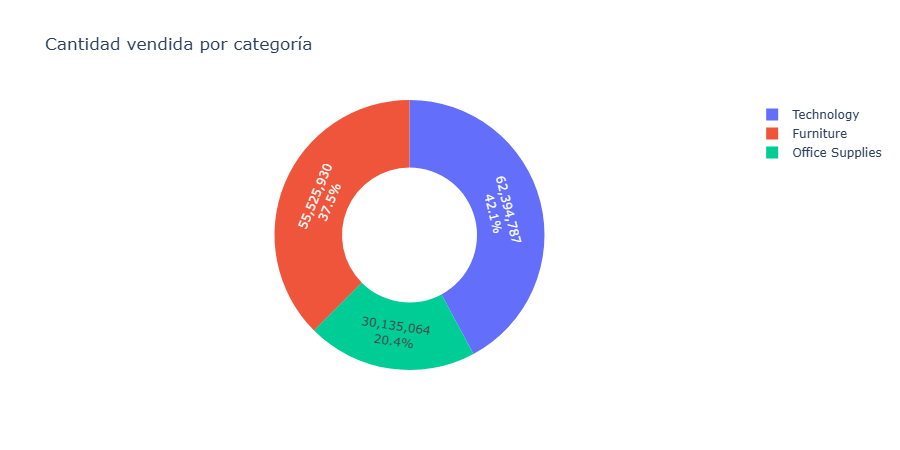

In [4]:
categorias = practica.ventas_por(con, "categoria")
fig = px.pie(categorias, names="categoria", values="cantidad_total", hole=0.5, title="Cantidad vendida por categoría")
fig.update_traces(texttemplate="%{value:,.0f}<br>%{percent:.1%}")
fig.show()

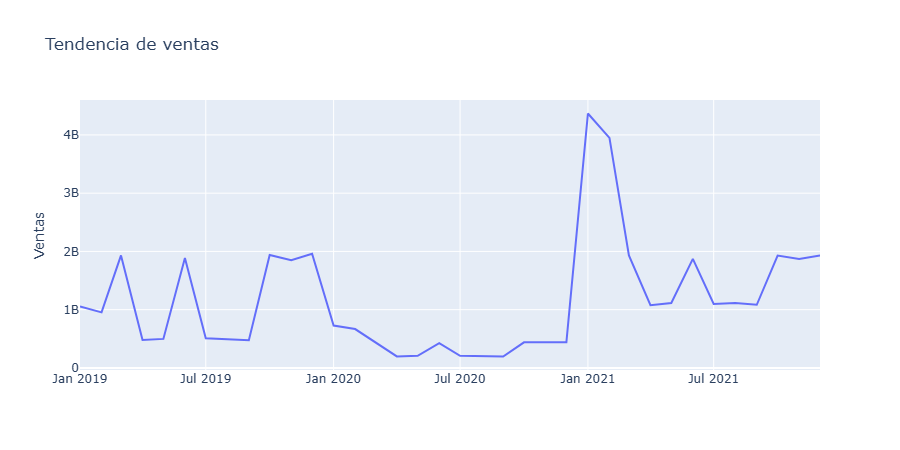

In [5]:
mensual = practica.serie_temporal(con, "month")
fig = px.line(mensual, x="periodo", y="ventas_total", title="Tendencia de ventas",
              labels={"periodo": "", "ventas_total": "Ventas"})
fig.show()

In [6]:
# El filtro de países debe afectar a todo: la suma por país reproduce el total
suma_paises = sum(practica.kpis(con, paises=[p])["ventas_total"] for p in mapa["pais"])
print("Suma de los diez países = total:", suma_paises == k["ventas_total"])
print("FRANCE:", millones(practica.kpis(con, paises=["FRANCE"])["ventas_total"]),
      "| meses en su serie:", len(practica.serie_temporal(con, "month", paises=["FRANCE"])))

Suma de los diez países = total: True
FRANCE: 6 709.5 M | meses en su serie: 36


Technology es la categoría con más unidades, seguida de Furniture y Office Supplies. La línea mensual muestra la caída de 2020 y el pico de enero y febrero de 2021. El filtro funciona: las ventas de cada país por separado suman exactamente el total, y con FRANCE la serie sigue cubriendo los 36 meses.

### Tarea 3. Tabla por país

In [7]:
tabla = practica.tabla_por_pais(con).sort_values("ventas_total", ascending=False, ignore_index=True)
tabla[["pais", "ventas_mediana", "ventas_total", "pct_cantidad"]]

,pais,ventas_mediana,ventas_total,pct_cantidad
0,FRANCE,22747.0,6709452115,0.100519
1,CANADA,22954.0,6683524091,0.100024
2,US,18060.0,5025305951,0.100565
3,BRAZIL,14735.0,4707983827,0.100333
4,CHILE,14679.0,4690608516,0.100027
5,MEXICO,14630.0,4655551012,0.099419
6,PORTUGAL,6460.0,2401536230,0.100849
7,SPAIN,6380.0,2360722916,0.099772
8,COLOMBIA,6372.0,2357431635,0.099644
9,PERU,6346.0,2348842532,0.098848


FRANCE y CANADA encabezan las ventas (unos 6 700 millones cada uno) y también la mediana por transacción. En cambio, el porcentaje de la cantidad apenas varía: los diez países venden entre el 9,9 % y el 10,1 % de las unidades, así que la diferencia de ventas viene del precio y no del volumen.

### Tarea 4. Formato condicional

In [8]:
from matplotlib.colors import LinearSegmentedColormap

NARANJA_AZUL = LinearSegmentedColormap.from_list("naranja_azul", ["#b35806", "#2166ac"])
uniforme = 1 / len(tabla)

vista = tabla.set_index("pais")[["ventas_mediana", "ventas_total", "pct_cantidad"]].assign(
    ventas_total=lambda t: t["ventas_total"] / 1e6
)
(
    vista.style
    .background_gradient(subset=["ventas_mediana"], cmap="Blues", vmin=0)
    .bar(subset=["ventas_total"], color="#9ecae1", vmin=0)
    .text_gradient(subset=["pct_cantidad"], cmap=NARANJA_AZUL, vmin=0.9 * uniforme, vmax=1.1 * uniforme)
    .format({"ventas_mediana": "{:,.0f}", "ventas_total": "{:,.1f} M", "pct_cantidad": "{:.2%}"})
)

,ventas_mediana,ventas_total,pct_cantidad
pais,,,
FRANCE,"22,747","6,709.5 M",10.05%
CANADA,"22,954","6,683.5 M",10.00%
US,"18,060","5,025.3 M",10.06%
BRAZIL,"14,735","4,708.0 M",10.03%
CHILE,"14,679","4,690.6 M",10.00%
MEXICO,"14,630","4,655.6 M",9.94%
PORTUGAL,"6,460","2,401.5 M",10.08%
SPAIN,"6,380","2,360.7 M",9.98%
COLOMBIA,"6,372","2,357.4 M",9.96%


La tabla usa los tres formatos: fondo azul en la mediana (de 0 al máximo), barras en el total y color de fuente en el porcentaje de cantidad, con límites a ±10 % del reparto uniforme para no exagerar diferencias de décimas. En la app las barras se piden con `ProgressColumn`, porque `st.dataframe` no dibuja las del `Styler`, y los límites se calculan sobre los diez países para que el color no cambie de significado al filtrar. GitHub no muestra los colores de este `Styler`; el gráfico siguiente transmite la misma lectura en PNG, con tres niveles según la participación en las ventas:

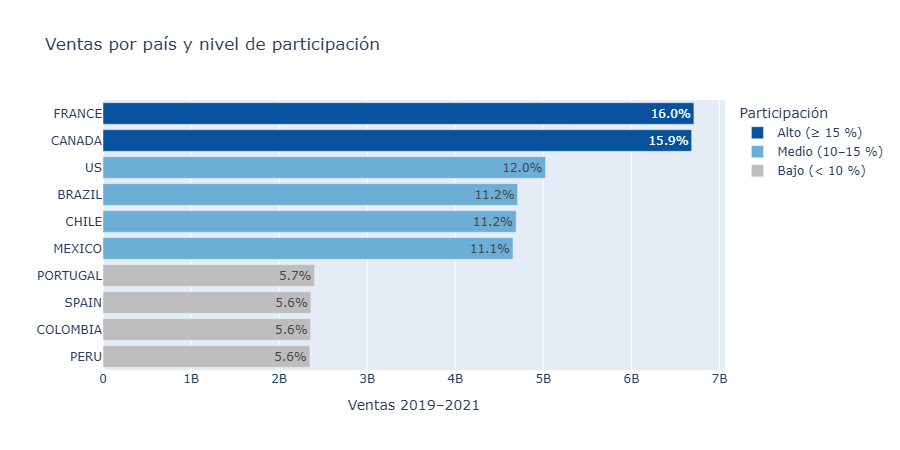

In [9]:
COLOR_NIVEL = {"Alto (≥ 15 %)": "#08519c", "Medio (10–15 %)": "#6baed6", "Bajo (< 10 %)": "#bdbdbd"}


def nivel(p):
    if p >= 0.15:
        return "Alto (≥ 15 %)"
    if p >= 0.10:
        return "Medio (10–15 %)"
    return "Bajo (< 10 %)"


barras = tabla.assign(pct_ventas=tabla["ventas_total"] / tabla["ventas_total"].sum())
barras["nivel"] = barras["pct_ventas"].map(nivel)
barras["etiqueta"] = barras["pct_ventas"].map("{:.1%}".format)
fig = px.bar(
    barras.sort_values("ventas_total"), x="ventas_total", y="pais", orientation="h", color="nivel",
    color_discrete_map=COLOR_NIVEL, text="etiqueta",
    category_orders={"nivel": list(COLOR_NIVEL), "pais": tabla["pais"].tolist()},  # de mayor a menor
    labels={"ventas_total": "Ventas 2019–2021", "pais": "", "nivel": "Participación"},
    title="Ventas por país y nivel de participación",
)
fig.show()

FRANCE (16,0 %) y CANADA (15,9 %) quedan en el nivel alto; US, BRAZIL, CHILE y MEXICO, en el medio, y los cuatro países restantes, por debajo del 10 %.

### Tarea 5. Exportar la tabla

In [10]:
csv = tabla.drop(columns="ventas_promedio").to_csv(index=False)
print(len(csv.encode("utf-8")), "bytes")
print("\n".join(csv.splitlines()[:4]))

658 bytes
pais,iso3,ventas_mediana,ventas_total,cantidad_total,pct_cantidad
FRANCE,FRA,22747.0,6709452115,14882353,0.10051855388206692
CANADA,CAN,22954.0,6683524091,14809154,0.10002415238348579
US,USA,18060.0,5025305951,14889285,0.10056537407343791


Ese es el contenido que entrega el `st.download_button` de la app con los diez países; con un filtro, la app descarga solo las filas filtradas. La prueba con `AppTest` ejecuta la app sin navegador:

In [11]:
import logging

from streamlit.testing.v1 import AppTest

# Silencia el aviso "missing ScriptRunContext", normal al ejecutar Streamlit fuera de un servidor
logging.getLogger("streamlit.runtime.scriptrunner_utils.script_run_context").setLevel(logging.ERROR)

app = AppTest.from_file(str(Path("m46-formato-condicional-app.py").resolve()), default_timeout=60).run()
print("Excepciones:", len(app.exception))
print("Título:", app.title[0].value)
print("Métricas:", [(m.label, m.value) for m in app.metric])
print("Botón de descarga:", app.download_button[0].label)

app.multiselect(key="paises").set_value(["PERU"]).run()
print("\nCon PERU. Excepciones:", len(app.exception))
print("Métricas:", [(m.label, m.value) for m in app.metric])
print("Filas de la tabla:", len(app.dataframe[0].value))

Excepciones: 0
Título: Mi primer dashboard
Métricas: [('Ventas totales', '41 941.0 M'), ('Cantidad total', '148.1 M'), ('Mediana del precio', '218')]
Botón de descarga: Descargar CSV



Con PERU. Excepciones: 0
Métricas: [('Ventas totales', '2 348.8 M'), ('Cantidad total', '14.6 M'), ('Mediana del precio', '98')]
Filas de la tabla: 1


La app arranca sin excepciones, muestra las tres métricas y el botón de descarga, y al filtrar PERU las métricas y la tabla cambian a ese país. Para verla en el navegador, desde la raíz del repositorio:

```bash
uv run streamlit run s08-dashboards/m46-formato-condicional/m46-formato-condicional-app.py
```

**Revisión posterior (2026-10):** El ejercicio se resolvió originalmente en Power BI, con un informe `.pbix`, la página exportada a PDF y capturas de pantalla como evidencia. Se rehízo en Python con pandas, DuckDB, Plotly y Streamlit para que la sección no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.